In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [43]:
url = "https://raw.githubusercontent.com/pplonski/datasets-for-start/refs/heads/master/insurance/insurance.csv"

df1 = pd.read_csv(url)

df1.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [44]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [45]:
df1.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [46]:
df1.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [47]:
df1.duplicated().sum()

np.int64(1)

In [52]:
df1 = df1.drop_duplicates()

df1["age"] = df1["age"].fillna(df1["age"].median())
df1["bmi"] = df1["bmi"].fillna(df1["bmi"].median())
df1["children"] = df1["children"].fillna(df1["children"].median())

df1 = df1.dropna()

In [53]:
df1 = pd.get_dummies(
    df1,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

df1.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [54]:
X1 = df1.drop("charges", axis=1)
y1 = df1["charges"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)

y1_pred = model1.predict(X1_test)

In [68]:
print("MAE:", mean_absolute_error(y1_test, y1_pred))
print("MSE:", mean_squared_error(y1_test, y1_pred))
print("RMSE:", np.sqrt(mean_squared_error(y1_test, y1_pred)))
print("R2 Score:", r2_score(y1_test, y1_pred))

MAE: 4177.045561036319
MSE: 35478020.67523561
RMSE: 5956.342894363588
R2 Score: 0.8069287081198011


In [56]:
results1 = pd.DataFrame({
    "Actual": y1_test.values,
    "Predicted": y1_pred
})

results1.head(10)

,Actual,Predicted
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


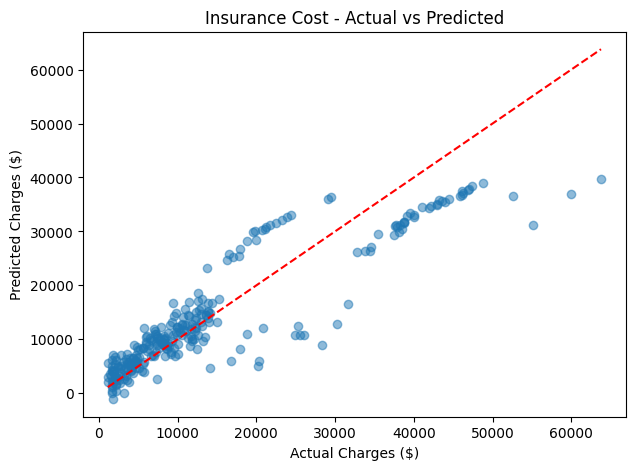

In [57]:
plt.figure(figsize=(7, 5))
plt.scatter(y1_test, y1_pred, alpha=0.5)

plt.plot(
    [y1_test.min(), y1_test.max()],
    [y1_test.min(), y1_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Charges ($)")
plt.ylabel("Predicted Charges ($)")
plt.title("Insurance Cost - Actual vs Predicted")
plt.show()

In [17]:
housing = fetch_california_housing(as_frame=True)
df2 = housing.frame

df2.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [18]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [19]:
df2.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [20]:
df2.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [21]:
df2.duplicated().sum()

np.int64(0)

In [22]:
df2.dtypes

,0
MedInc,float64
HouseAge,float64
AveRooms,float64
AveBedrms,float64
Population,float64
AveOccup,float64
Latitude,float64
Longitude,float64
MedHouseVal,float64


In [23]:
df2 = df2.drop_duplicates()

In [24]:
df2 = df2.fillna(df2.median())

In [25]:
X2 = df2.drop("MedHouseVal", axis=1)
y2 = df2["MedHouseVal"]

In [26]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

In [27]:
model2 = LinearRegression()
model2.fit(X2_train, y2_train)

LinearRegression()

In [28]:
y2_pred = model2.predict(X2_test)

y2_pred[:5]

array([0.71912284, 1.76401657, 2.70965883, 2.83892593, 2.60465725])

In [29]:
mae2 = mean_absolute_error(y2_test, y2_pred)
mse2 = mean_squared_error(y2_test, y2_pred)
rmse2 = np.sqrt(mse2)
r2_2 = r2_score(y2_test, y2_pred)

print("MAE:", mae2)
print("MSE:", mse2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)

MAE: 0.5332001304956553
MSE: 0.5558915986952444
RMSE: 0.7455813830127764
R2 Score: 0.5757877060324508


In [30]:
results2 = pd.DataFrame({
    "Actual": y2_test.values,
    "Predicted": y2_pred
})

results2.head(10)

,Actual,Predicted
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


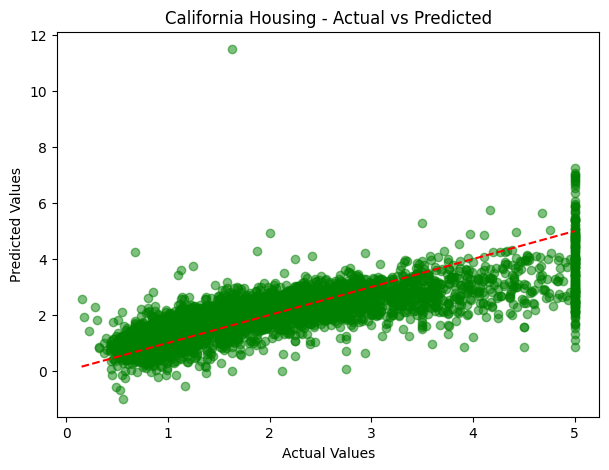

In [31]:
plt.figure(figsize=(7, 5))

plt.scatter(y2_test, y2_pred, color="green", alpha=0.5)

plt.plot(
    [y2_test.min(), y2_test.max()],
    [y2_test.min(), y2_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("California Housing - Actual vs Predicted")
plt.show()

In [32]:
!pip install -q gradio

In [33]:
import gradio as gr

In [34]:
# Diabetes prediction
def predict_diabetes(age, sex, bmi, bp, s1, s2, s3, s4, s5, s6):

    values = [[age, sex, bmi, bp, s1, s2, s3, s4, s5, s6]]

    data = pd.DataFrame(values, columns=X1.columns)

    prediction = model1.predict(data)

    return round(float(prediction[0]), 2)


# California Housing prediction
def predict_housing(MedInc, HouseAge, AveRooms, AveBedrms,
                    Population, AveOccup, Latitude, Longitude):

    values = [[MedInc, HouseAge, AveRooms, AveBedrms,
               Population, AveOccup, Latitude, Longitude]]

    data = pd.DataFrame(values, columns=X2.columns)

    prediction = model2.predict(data)

    return round(float(prediction[0]) * 100000, 2)

In [58]:

import gradio as gr

# Insurance prediction
def predict_insurance(age, sex, bmi, children, smoker, region):

    data = pd.DataFrame([{
        "age": age,
        "sex": sex,
        "bmi": bmi,
        "children": children,
        "smoker": smoker,
        "region": region
    }])

    data = pd.get_dummies(
        data,
        columns=["sex", "smoker", "region"],
        dtype=int
    )

    data = data.reindex(columns=X1.columns, fill_value=0)

    # Correctly encode the selected categories
    for column in X1.columns:
        if column.startswith("sex_"):
            data[column] = int(column == "sex_" + sex)
        elif column.startswith("smoker_"):
            data[column] = int(column == "smoker_" + smoker)
        elif column.startswith("region_"):
            data[column] = int(column == "region_" + region)

    prediction = model1.predict(data)[0]
    return round(float(prediction), 2)


# Housing prediction
def predict_housing(*values):

    data = pd.DataFrame([values], columns=X2.columns)

    prediction = model2.predict(data)[0]

    return round(float(prediction) * 100000, 2)


with gr.Blocks(title="Linear Regression Lab") as demo:

    gr.Markdown("# Linear Regression Prediction System")

    with gr.Tab("Insurance Cost Prediction"):

        gr.Markdown("## Medical Insurance Cost Prediction")

        with gr.Row():
            with gr.Column():
                age = gr.Slider(18, 64, value=25, step=1, label="Age")
                sex = gr.Dropdown(
                    ["male", "female"], value="male", label="Sex"
                )
                bmi = gr.Number(value=25.0, label="BMI")

            with gr.Column():
                children = gr.Slider(
                    0, 5, value=0, step=1, label="Children"
                )
                smoker = gr.Dropdown(
                    ["yes", "no"], value="no", label="Smoker"
                )
                region = gr.Dropdown(
                    ["northeast", "northwest", "southeast", "southwest"],
                    value="northeast",
                    label="Region"
                )

        insurance_output = gr.Number(
            label="Predicted Insurance Charges ($)"
        )

        gr.Button("Predict Insurance Cost", variant="primary").click(
            predict_insurance,
            inputs=[age, sex, bmi, children, smoker, region],
            outputs=insurance_output
        )

    with gr.Tab("Housing Price Prediction"):

        gr.Markdown("## California Housing Price Prediction")

        housing_inputs = []

        with gr.Row():
            for features in [X2.columns[:4], X2.columns[4:]]:
                with gr.Column():
                    for feature in features:
                        box = gr.Number(
                            label=feature,
                            value=round(float(X2[feature].median()), 2)
                        )
                        housing_inputs.append(box)

        housing_output = gr.Number(
            label="Predicted House Value ($)"
        )

        gr.Button("Predict House Price", variant="primary").click(
            predict_housing,
            inputs=housing_inputs,
            outputs=housing_output
        )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0a77c21cc731ae71fd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9337779959f91f78b9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [59]:
!pip install -q flask pyngrok

In [60]:
from flask import Flask, request, render_template_string
from pyngrok import ngrok
import threading
import pandas as pd

In [62]:

app = Flask(__name__)

HTML = """
<!DOCTYPE html>
<html>
<head>
    <title>Linear Regression Prediction</title>
    <style>
        body {
            font-family: Arial, sans-serif;
            background: #f1f5f9;
            padding: 30px;
        }
        .container {
            max-width: 650px;
            margin: auto;
            background: white;
            padding: 30px;
            border-radius: 15px;
            box-shadow: 0 4px 15px #ddd;
        }
        h1 { color: #1e293b; }
        label {
            display: block;
            margin-top: 15px;
            font-weight: bold;
        }
        input, select, button {
            width: 100%;
            padding: 12px;
            margin-top: 5px;
            box-sizing: border-box;
            border: 1px solid #ddd;
            border-radius: 7px;
        }
        button {
            background: #2563eb;
            color: white;
            border: none;
            margin-top: 20px;
            cursor: pointer;
            font-size: 16px;
        }
        .result {
            background: #dbeafe;
            padding: 18px;
            border-radius: 8px;
            margin-top: 20px;
            font-size: 20px;
        }
    </style>
</head>
<body>
<div class="container">

    <h1>Linear Regression Prediction System</h1>

    <form method="POST">

        <label>Select Dataset</label>
        <select name="dataset" onchange="this.form.submit()">
            <option value="insurance"
                {% if dataset == 'insurance' %}selected{% endif %}>
                Insurance Cost Prediction
            </option>
            <option value="housing"
                {% if dataset == 'housing' %}selected{% endif %}>
                California Housing Prediction
            </option>
        </select>

        {% if dataset == 'insurance' %}

            <label>Age</label>
            <input type="number" name="age" value="25" min="18" max="64" required>

            <label>Sex</label>
            <select name="sex">
                <option value="male">Male</option>
                <option value="female">Female</option>
            </select>

            <label>BMI</label>
            <input type="number" step="any" name="bmi" value="25" required>

            <label>Number of Children</label>
            <input type="number" name="children" value="0" min="0" max="5" required>

            <label>Smoker</label>
            <select name="smoker">
                <option value="no">No</option>
                <option value="yes">Yes</option>
            </select>

            <label>Region</label>
            <select name="region">
                <option value="northeast">Northeast</option>
                <option value="northwest">Northwest</option>
                <option value="southeast">Southeast</option>
                <option value="southwest">Southwest</option>
            </select>

        {% else %}

            {% for feature, value in housing_features %}
                <label>{{ feature }}</label>
                <input type="number" step="any"
                       name="{{ feature }}"
                       value="{{ value }}" required>
            {% endfor %}

        {% endif %}

        <button type="submit" name="action" value="predict">
            Predict
        </button>

    </form>

    {% if prediction is not none %}
        <div class="result">
            <strong>Predicted Value: ${{ prediction }}</strong>
        </div>
    {% endif %}

</div>
</body>
</html>
"""


@app.route("/", methods=["GET", "POST"])
def home():

    dataset = request.form.get("dataset", "insurance")
    prediction = None

    if request.form.get("action") == "predict":

        if dataset == "insurance":

            age = int(request.form["age"])
            sex = request.form["sex"]
            bmi = float(request.form["bmi"])
            children = int(request.form["children"])
            smoker = request.form["smoker"]
            region = request.form["region"]

            prediction = predict_insurance(
                age, sex, bmi, children, smoker, region
            )

        else:

            values = [
                float(request.form[feature])
                for feature in X2.columns
            ]

            prediction = predict_housing(*values)

    housing_features = [
        (feature, round(float(X2[feature].median()), 2))
        for feature in X2.columns
    ]

    return render_template_string(
        HTML,
        dataset=dataset,
        prediction=prediction,
        housing_features=housing_features
    )


In [65]:
from google.colab import userdata
from pyngrok import ngrok

ngrok.set_auth_token(userdata.get("NGROK_AUTH_TOKEN"))

In [67]:
def run_flask():
    app.run(port=5000, use_reloader=False)

threading.Thread(target=run_flask, daemon=True).start()

public_url = ngrok.connect(5000)

print("Flask Website:", public_url.public_url)

 * Serving Flask app '__main__'
 * Debug mode: off
Flask Website: https://reconvene-revocable-valid.ngrok-free.dev


Address already in use
Port 5000 is in use by another program. Either identify and stop that program, or start the server with a different port.
